# Week 2 – Data Preparation for Machine Learning


In [68]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)   # charts are saved here for the report

## Step 1

In [69]:
df = pd.read_csv("loan_prediction.csv")
print("Shape:", df.shape)
df.head()

Shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [71]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [72]:
# describe() only shows numbers, so I also check the text columns
df.select_dtypes(exclude="number").describe()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP002990,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


**Target distribution** – I check if the classes are balanced, because this decides if I need `stratify` later.

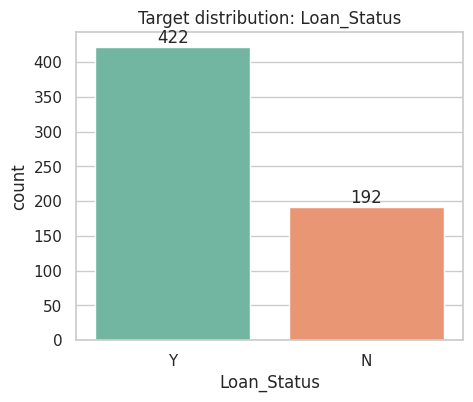

Loan_Status
Y    0.687
N    0.313
Name: proportion, dtype: float64


In [73]:
plt.figure(figsize=(5,4))
ax = sns.countplot(data=df, x="Loan_Status", hue="Loan_Status", palette="Set2", legend=False)
for c in ax.containers: ax.bar_label(c)
plt.title("Target distribution: Loan_Status")
plt.savefig("figures/01_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(df["Loan_Status"].value_counts(normalize=True).round(3))

**Chart 2 – Loan status by Credit History.** I expect people with a good credit history to get approved more often.

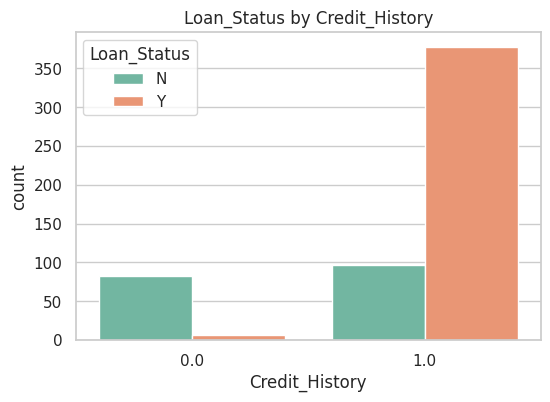

In [74]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Credit_History", hue="Loan_Status", palette="Set2")
plt.title("Loan_Status by Credit_History")
plt.savefig("figures/02_status_by_credit_history.png", dpi=150, bbox_inches="tight")
plt.show()

**Chart 3 – Histogram of ApplicantIncome.** I want to see the shape (skew) and outliers of income.

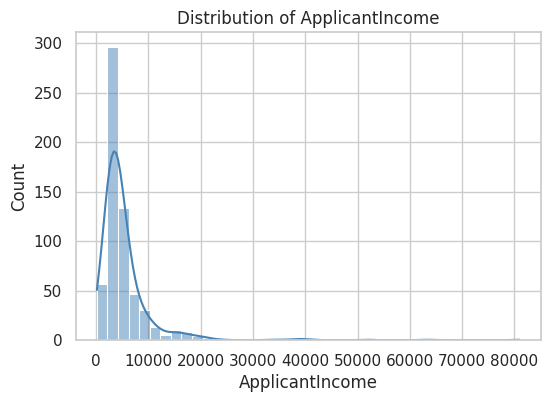

In [75]:
plt.figure(figsize=(6,4))
sns.histplot(df["ApplicantIncome"], bins=40, kde=True, color="steelblue")
plt.title("Distribution of ApplicantIncome")
plt.savefig("figures/03_applicant_income_hist.png", dpi=150, bbox_inches="tight")
plt.show()

**Chart 4 – Correlation heatmap** of the numeric columns.

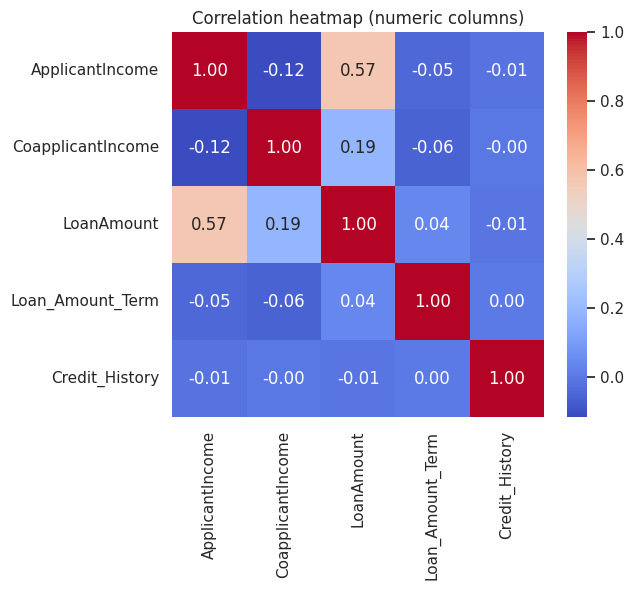

In [76]:
plt.figure(figsize=(6,5))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap (numeric columns)")
plt.savefig("figures/04_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**What I noticed**
- The target is imbalanced: about 69% of loans are approved (Y) and 31% rejected (N), so I will use `stratify=y`.
- `Credit_History` looks like the strongest signal: about 80% of applicants with history = 1 are approved, but only about 8% of those with history = 0.
- `ApplicantIncome` is heavily right-skewed (a few very high incomes), so scaling is important.
- `LoanAmount` and `ApplicantIncome` have a moderate correlation (about 0.57), which makes sense because bigger earners ask for bigger loans. No pair of columns is almost identical, so I do not need to remove any for being duplicates of each other.

## Step 2 – Clean the data
Here I'm goona remove duplicate rows then count missing values and plot them after that drop useless columns and decide what to do with each column that has missing values.

In [77]:
dups = df.duplicated().sum()
print("Duplicate rows:", dups)
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (614, 13)


Credit_History      50
Self_Employed       32
LoanAmount          22
Dependents          15
Loan_Amount_Term    14
Gender              13
Married              3
dtype: int64


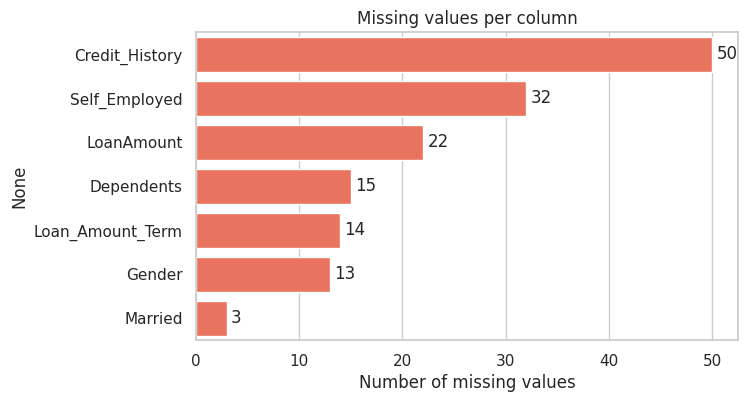

In [78]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

plt.figure(figsize=(7,4))
ax = sns.barplot(x=missing.values, y=missing.index, color="tomato")
for c in ax.containers: ax.bar_label(c, padding=3)
plt.title("Missing values per column")
plt.xlabel("Number of missing values")
plt.savefig("figures/05_missing_values.png", dpi=150, bbox_inches="tight")
plt.show()

**Drop useless columns:** `Loan_ID` is only a unique label for each row. It has no meaning for prediction and
could even let the model memorise rows, so I drop it.

In [79]:
df = df.drop(columns=["Loan_ID"])
df.columns.tolist()

['Gender',
 'Married',
 'Dependents',
 'Education',
 'Self_Employed',
 'ApplicantIncome',
 'CoapplicantIncome',
 'LoanAmount',
 'Loan_Amount_Term',
 'Credit_History',
 'Property_Area',
 'Loan_Status']

**Decision for every column with missing values**

| Column | Missing | Decision | Why |
|---|---|---|---|
| Credit_History | 50 | Fill with most frequent value | Only 0/1 values, so it is a category. A median/mean would make no sense. Dropping the column would lose the strongest feature, dropping rows would lose 8% of data. |
| Self_Employed | 32 | Fill with most frequent value | Text category, about 86% are "No", so the mode is a safe guess. |
| LoanAmount | 22 | Fill with median | Numeric and right-skewed with outliers, so the median is safer than the mean. |
| Dependents | 15 | Fill with most frequent value | Category ("0", "1", "2", "3+"); the mode is "0". |
| Loan_Amount_Term | 14 | Fill with median | Numeric; most values are 360, the median keeps it. |
| Gender | 13 | Fill with most frequent value | Text category; very few missing. |
| Married | 3 | Fill with most frequent value | Only 3 rows, so any simple fill has almost no effect. |

I did **not** drop any column or row: each column has under 10% missing and every one of them carries useful information.
The actual filling is done inside the preprocessing pipeline (Step 6) and learned on the **train data only**, so no information leaks from the test set.

## Step 3 – Feature engineering
I create three new features from the existing columns. Each one is calculated row by row, so it does not use
information from other rows and cannot cause data leakage.

In [80]:
# Total household income
df["TotalIncome"] = df["ApplicantIncome"] + df["CoapplicantIncome"]

#  Approximate monthly instalment
df["EMI"] = df["LoanAmount"] / df["Loan_Amount_Term"]

# 3) How big is the loan compared to income
df["LoanToIncome"] = df["LoanAmount"] / df["TotalIncome"]

df[["ApplicantIncome","CoapplicantIncome","TotalIncome","LoanAmount","Loan_Amount_Term","EMI","LoanToIncome"]].head()

,ApplicantIncome,CoapplicantIncome,TotalIncome,LoanAmount,Loan_Amount_Term,EMI,LoanToIncome
0,5849,0.0,5849.0,NaN,360.0,NaN,NaN
1,4583,1508.0,6091.0,128.0,360.0,0.355556,0.021015
2,3000,0.0,3000.0,66.0,360.0,0.183333,0.022000
3,2583,2358.0,4941.0,120.0,360.0,0.333333,0.024287
4,6000,0.0,6000.0,141.0,360.0,0.391667,0.023500


**Why these features can help**
**TotalIncome:** a bank looks at the whole household's income, not only the applicant's. A person with low income but a rich co-applicant is a safe borrower, and the model cannot see this from the two separate columns easily.
**EMI:** it shows how much has to be paid each month. The same loan amount is easy or hard to pay depending on the term.
**LoanToIncome:** the ratio tells how heavy the loan is compared to what the family earns. A high ratio means more risk, which is what the bank cares about.

## Step 4 – Select features and target


In [81]:
y = df["Loan_Status"].map({"Y": 1, "N": 0})
X = df.drop(columns=["Loan_Status"])

# Credit_History is stored as 0.0/1.0 but it really means "has a good history or not" -> treat as category
X["Credit_History"] = X["Credit_History"].astype("object")

print("X shape:", X.shape, "| y shape:", y.shape)
X.head()

X shape: (614, 14) | y shape: (614,)


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,TotalIncome,EMI,LoanToIncome
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,5849.0,NaN,NaN
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,6091.0,0.355556,0.021015
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,3000.0,0.183333,0.022000
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,4941.0,0.333333,0.024287
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,6000.0,0.391667,0.023500


## Step 5 – Train/test split


In [82]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])
print("\nClass proportions (1 = approved):")
print("Full  :", y.value_counts(normalize=True).round(3).to_dict())
print("Train :", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test  :", y_test.value_counts(normalize=True).round(3).to_dict())

Train size: 491 | Test size: 123

Class proportions (1 = approved):
Full  : {1: 0.687, 0: 0.313}
Train : {1: 0.686, 0: 0.314}
Test  : {1: 0.691, 0: 0.309}


## Step 6 – Preprocessing (fit on TRAIN only)


In [83]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric    :", num_cols)
print("Categorical:", cat_cols)

Numeric    : ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'TotalIncome', 'EMI', 'LoanToIncome']
Categorical: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Credit_History', 'Property_Area']


In [84]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
]).set_output(transform="pandas")

X_train_p = preprocessor.fit_transform(X_train)   # learn from TRAIN and transform it
X_test_p  = preprocessor.transform(X_test)        # only transform TEST (no learning)

X_train_p.head()

,num__ApplicantIncome,num__CoapplicantIncome,num__LoanAmount,num__Loan_Amount_Term,num__TotalIncome,num__EMI,num__LoanToIncome,cat__Gender_Female,cat__Gender_Male,cat__Married_No,...,cat__Dependents_3+,cat__Education_Graduate,cat__Education_Not Graduate,cat__Self_Employed_No,cat__Self_Employed_Yes,cat__Credit_History_0.0,cat__Credit_History_1.0,cat__Property_Area_Rural,cat__Property_Area_Semiurban,cat__Property_Area_Urban
154,-0.352802,-0.563228,-1.131588,0.280691,-0.575168,-0.621290,-1.075977,0.0,1.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
239,-0.343346,-0.563228,-0.592309,0.280691,-0.566044,-0.391688,0.711178,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
448,-0.339471,0.050405,0.040758,0.280691,-0.306544,-0.122155,0.808952,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
471,-0.445963,-0.024953,-0.393010,-2.486768,-0.440706,0.257188,0.481101,0.0,1.0,0.0,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
273,-0.451078,0.234495,0.040758,0.280691,-0.337505,-0.122155,0.975863,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0


## Step 7 – Final checks
I print the shapes, confirm that there are no missing values, and prove that nothing was fitted on the test data.

In [85]:
print("X_train:", X_train_p.shape)
print("X_test :", X_test_p.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (491, 24)
X_test : (123, 24)
y_train: (491,)
y_test : (123,)


In [86]:
print("Missing values in X_train:", X_train_p.isnull().sum().sum())
print("Missing values in X_test :", X_test_p.isnull().sum().sum())
assert X_train_p.isnull().sum().sum() == 0 and X_test_p.isnull().sum().sum() == 0

Missing values in X_train: 0
Missing values in X_test : 0


In [87]:
# Proof 1: the scaler has only seen as many rows as the TRAIN set
scaler = preprocessor.named_transformers_["num"].named_steps["scaler"]
print("Rows seen by scaler:", scaler.n_samples_seen_, "| Train rows:", len(X_train))
assert scaler.n_samples_seen_ == len(X_train)

# Proof 2: the median used for filling is the TRAIN median, not the test one
imp = preprocessor.named_transformers_["num"].named_steps["imputer"]
i = num_cols.index("LoanAmount")
print("LoanAmount median used (train):", imp.statistics_[i])
print("LoanAmount median of test data:", X_test["LoanAmount"].median())

# Proof 3: train is exactly standardised, test is only close (because it used train's mean/std)
print("Train mean of scaled ApplicantIncome:", round(X_train_p["num__ApplicantIncome"].mean(), 4))
print("Test  mean of scaled ApplicantIncome:", round(X_test_p["num__ApplicantIncome"].mean(), 4))

Rows seen by scaler: 491 | Train rows: 491
LoanAmount median used (train): 128.0
LoanAmount median of test data: 123.0
Train mean of scaled ApplicantIncome: -0.0
Test  mean of scaled ApplicantIncome: -0.0979


In [88]:
X_train, X_test = X_train_p, X_test_p     # final names asked in the task
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(491, 24) (123, 24) (491,) (123,)
